In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [19]:
df = pd.read_csv("creditcard.csv")


if not pd.api.types.is_numeric_dtype(df["Class"]):
    df["Class"] = df["Class"].astype(str).str.strip("'\"").astype(int)

print("Rows, columns:", df.shape)# df.shape gives (number of rows, number of columns)

df.head()

Rows, columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [20]:
print("Missing values:", df.isna().sum().sum())

dup_mask = df.duplicated()
print("Duplicate rows:", dup_mask.sum())

print(df.loc[dup_mask, "Class"].value_counts())

Missing values: 0
Duplicate rows: 1081
Class
0    1062
1      19
Name: count, dtype: int64


Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.173%
A model that always says 'not fraud' would be 99.83% accurate


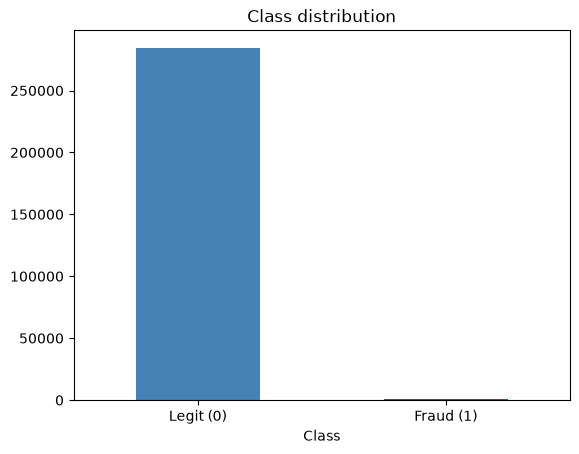

In [21]:
counts = df["Class"].value_counts().sort_index()

# Class is only 0s and 1s, so its average is the share of 1s = the fraud rate
fraud_rate = df["Class"].mean()
print(counts)
print(f"Fraud rate: {fraud_rate * 100:.3f}%")
print(f"A model that always says 'not fraud' would be {(1 - fraud_rate) * 100:.2f}% accurate")


counts.plot(kind="bar", color=["steelblue", "crimson"])
plt.xticks([0, 1], ["Legit (0)", "Fraud (1)"], rotation=0)
plt.title("Class distribution")
plt.show()

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


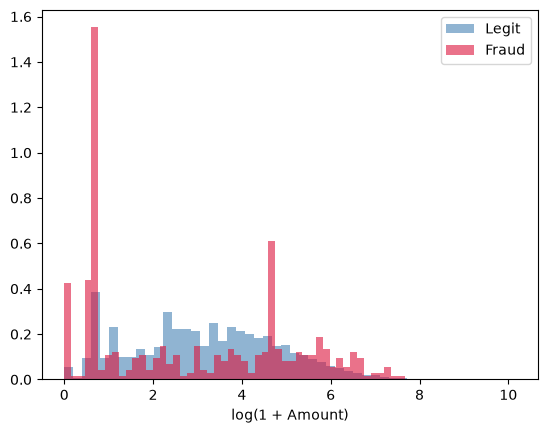

In [22]:
# count, mean, spread (std), min, quartiles (25%, 50%, 75%) and max
print(df.groupby("Class")["Amount"].describe().round(2))

# 2 loops ,one is legit next one for fraud, drawing each histogram on the same chart
for cls, colour, label in [(0, "steelblue", "Legit"), (1, "crimson", "Fraud")]:
    # The Amount of only the rows where Class equals cls
    amounts = df.loc[df["Class"] == cls, "Amount"]

    # np.log1p(x) = log(1 + x). shrinking huge amounts and making chart readeble
    # density=True, each histogram adds up to 1, so the tiny fraud group is comparable to legit.
    plt.hist(np.log1p(amounts), bins=50, alpha=0.6, density=True, color=colour, label=label)

plt.xlabel("log(1 + Amount)")
plt.legend()
plt.show()

           sum   mean
HourOfDay            
0.0          6  0.078
1.0         10  0.237
2.0         57  1.713
3.0         17  0.487
4.0         23  1.041
5.0         11  0.368
6.0          9  0.219
7.0         23  0.318
8.0          9  0.088
9.0         16  0.101
10.0         8  0.048
11.0        53  0.314
12.0        17  0.110
13.0        17  0.111
14.0        23  0.139
15.0        26  0.158
16.0        22  0.134
17.0        29  0.179
18.0        33  0.194
19.0        19  0.121
20.0        18  0.107
21.0        16  0.090
22.0         9  0.058
23.0        21  0.192


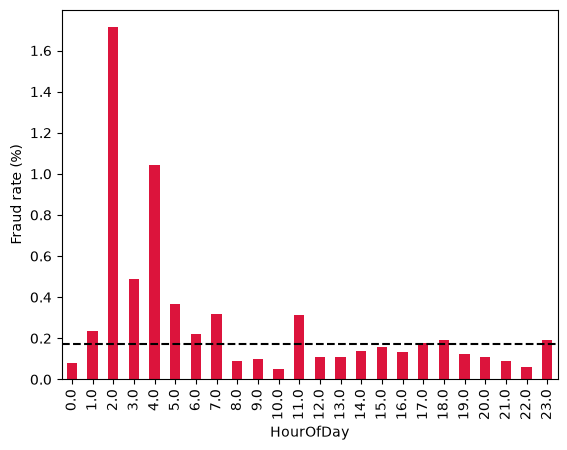

In [23]:
# converting time to hours
df["HourOfDay"] = (df["Time"] // 3600) % 24

# For each hour: sum = number of frauds, mean = fraud rate
by_hour = df.groupby("HourOfDay")["Class"].agg(["sum", "mean"])
by_hour["mean"] = by_hour["mean"] * 100   # turn the rate into a percentage
print(by_hour.round(3))

by_hour["mean"].plot(kind="bar", color="crimson")
plt.axhline(fraud_rate * 100, color="black", linestyle="--")
plt.ylabel("Fraud rate (%)")
plt.show()

Most negative:
 V17   -0.326
V14   -0.303
V12   -0.261
V10   -0.217
V16   -0.197
dtype: float64

Most positive:
 V19    0.035
V21    0.040
V2     0.091
V4     0.133
V11    0.155
dtype: float64


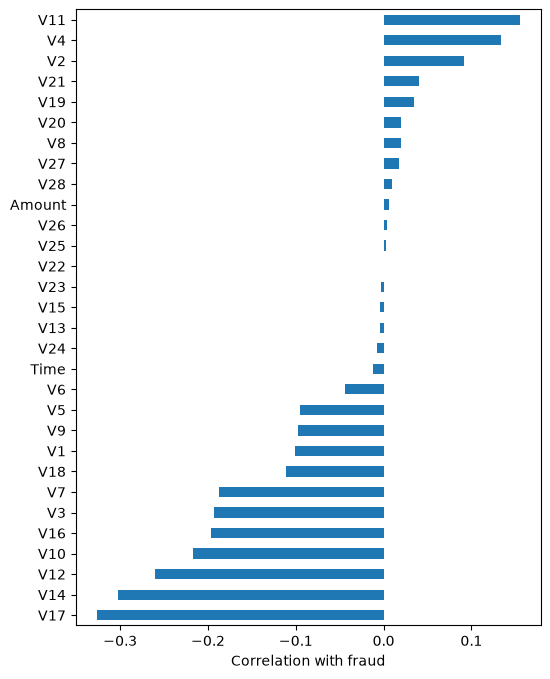

In [24]:

feature_cols = [c for c in df.columns if c.startswith("V")] + ["Amount", "Time"]

# .corrwith(df["Class"]) = correlation of each feature with Class.
# .sort_values() orders them from most negative to most positive.
corr_with_class = df[feature_cols].corrwith(df["Class"]).sort_values()

print("Most negative:\n", corr_with_class.head(5).round(3))
print("\nMost positive:\n", corr_with_class.tail(5).round(3))

# Horizontal bar chart. figsize=(width, height) makes it tall enough for 30 labels.
corr_with_class.plot(kind="barh", figsize=(6, 8))
plt.xlabel("Correlation with fraud")
plt.show()

Top 4 features: ['V17', 'V14', 'V12', 'V10']


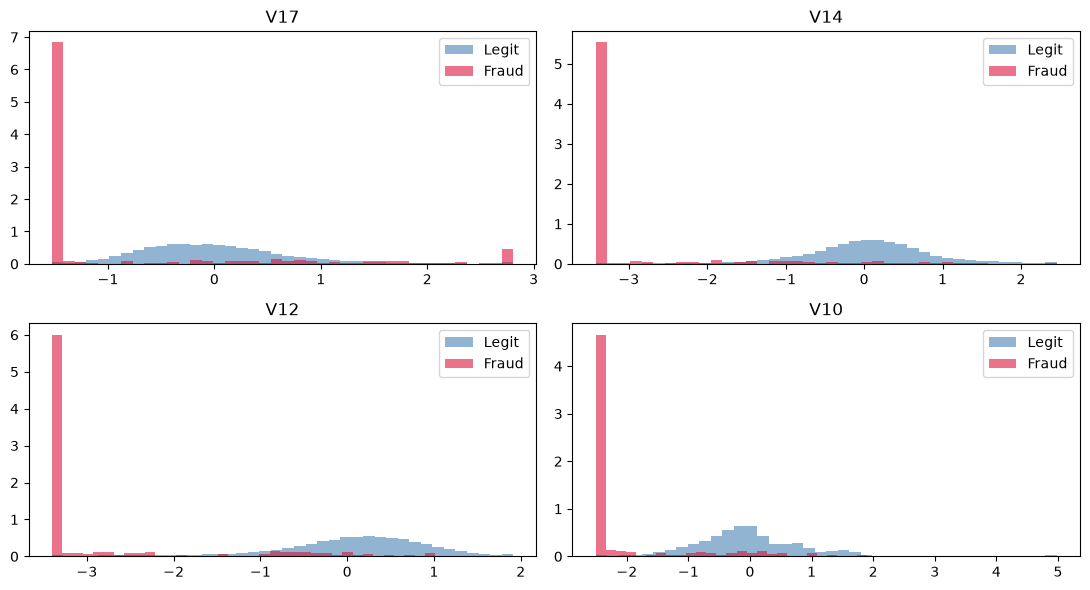

In [25]:
# .abs() ignores the sign (so -0.3 counts as strong as +0.3), sort_values(ascending=False) puts
# the biggest first, .head(4) keeps the top 4, and .index.tolist() turns their names into a list.
top4 = corr_with_class.abs().sort_values(ascending=False).head(4).index.tolist()
print("Top 4 features:", top4)

fig, axes = plt.subplots(2, 2, figsize=(11, 6))

# axes.ravel() flattens the 2x2 grid into a simple list; zip pairs each chart area with a feature name
for ax, feat in zip(axes.ravel(), top4):
    # The 0.5th and 99.5th percentile values. We use them so a few extreme outliers don't stretch the chart.
    lo, hi = df[feat].quantile([0.005, 0.995])

    for cls, colour, label in [(0, "steelblue", "Legit"), (1, "crimson", "Fraud")]:
        # .clip(lo, hi) squeezes any value outside that range back to the edge
        vals = df.loc[df["Class"] == cls, feat].clip(lo, hi)
        ax.hist(vals, bins=40, alpha=0.6, density=True, color=colour, label=label)

    ax.set_title(feat)
    ax.legend()

# tight_layout stops the 4 charts overlapping each other
plt.tight_layout()
plt.show()

In [26]:
# .describe() gives summary stats. .T flips the table so each column becomes a row (easier to read).
# The last [[...]] keeps only the four stats we care about.
df[["Time", "Amount", "V1", "V2", "V28"]].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
Time,94813.86,47488.15,0.00,172792.00
Amount,88.35,250.12,0.00,25691.16
V1,0.00,1.96,-56.41,2.45
V2,0.00,1.65,-72.72,22.06
V28,-0.00,0.33,-15.43,33.85


## 9. Your findings (fill this in)

Write these in your own words. It's what turns running code into understanding, and it becomes the "Key findings" part of your README.

1. Fraud rate: 0.173%
2. Duplicate rows: 1081 (of which fraud: 19)
3. Median Amount, fraud vs legit: ______ vs ______
4. Any hour that looks riskier? 2.0 , sum = 57, mean= 1.713
5. Top 4 features linked to fraud: ['V17', 'V14', 'V12', 'V10']
6. Columns that need scaling: ______

When you've run it, paste the printed numbers back into the chat and we'll go through them together.

In [27]:
import pandas as pd
import numpy as np

# train_test_split does the splitting. RobustScaler does the scaling.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

In [28]:
# Read the CSV into a table called df
df = pd.read_csv("creditcard.csv")

# Same fix as before: if Class loaded as text like '0', convert it to a number
if not pd.api.types.is_numeric_dtype(df["Class"]):
    df["Class"] = df["Class"].astype(str).str.strip("'\"").astype(int)

print("Rows before dropping duplicates:", len(df))

# drop_duplicates() keeps the first copy of each row and removes the rest
df = df.drop_duplicates()

print("Rows after dropping duplicates: ", len(df))
# .sum() adds up the 1s in Class, so this is the number of fraud rows left
print("Fraud rows remaining:           ", df["Class"].sum())

Rows before dropping duplicates: 284807
Rows after dropping duplicates:  283726
Fraud rows remaining:            473


In [29]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [30]:
# drop(columns=["Class"]) = the whole table, minus the Class column
X = df.drop(columns=["Class"])

# Just the Class column
y = df["Class"]

print("X shape (rows, columns):", X.shape)
print("y shape (rows,):        ", y.shape)

X shape (rows, columns): (283726, 30)
y shape (rows,):         (283726,)


In [31]:
# train_test_split returns four things, in this exact order
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% of rows go to the test set
    stratify=y,          # keep the same fraud percentage in both sets
    random_state=42,     # makes the shuffle repeatable
)

# Check the sizes and the fraud rate in each set
# .mean() of a column of 0s and 1s = the share of 1s = fraud rate
print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds, fraud rate {y_train.mean() * 100:.3f}%")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} frauds, fraud rate {y_test.mean() * 100:.3f}%")

Train: 226,980 rows, 378 frauds, fraud rate 0.167%
Test:  56,746 rows, 95 frauds, fraud rate 0.167%


In [32]:
# .copy() makes independent copies so pandas doesn't warn us about editing a slice
X_train = X_train.copy()
X_test = X_test.copy()
cols_to_scale = ["Time", "Amount"]

scaler = RobustScaler()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Done. Scaler learned these medians from the training data:", scaler.center_.round(2))

Done. Scaler learned these medians from the training data: [8.4816e+04 2.2080e+01]


In [33]:

print("TRAIN (scaled columns):")
print(X_train[cols_to_scale].describe().round(2))

print("\nTEST (scaled columns):")
print(X_test[cols_to_scale].describe().round(2))

TRAIN (scaled columns):
            Time     Amount
count  226980.00  226980.00
mean        0.12       0.92
std         0.56       3.41
min        -1.00      -0.31
25%        -0.36      -0.23
50%         0.00       0.00
75%         0.64       0.77
max         1.03     272.10

TEST (scaled columns):
           Time    Amount
count  56746.00  56746.00
mean       0.11      0.92
std        0.56      3.72
min       -1.00     -0.31
25%       -0.36     -0.23
50%       -0.00     -0.01
75%        0.64      0.75
max        1.03    355.72


In [34]:
X_train.assign(Class=y_train).to_csv("train.csv", index=False)
X_test.assign(Class=y_test).to_csv("test.csv", index=False)

print("Saved train.csv and test.csv in this folder")

Saved train.csv and test.csv in this folder
